# Recursive world models — experiment ledger and CPU-first iteration
**Revision 2 · 25 November 2026** | Start here. The original executed Kaggle notebook, including its outputs, plots and profiling, is preserved in Appendix A. Its code is disabled by default. Nothing in the archive is evidence for the new variant.

**Research question:** can discovered executable knowledge become input to subsequent learning, including revising the meaning and applicability of earlier knowledge? The eventual system must learn not just operations, but transformations of operations, and reuse them to acquire more knowledge.

**Method:** fast.ai/Jeremy Howard-inspired workflow: establish a competent baseline; predict outcomes before running; inspect examples; verify the smallest mechanism on CPU; use one cached neural pass; compare one change at a time; only profile/scale after a meaningful win. These are our experimental choices, not claims about Howard endorsing this architecture.

**Run order:** sections 1–3 are CPU only. Section 4 optionally reads actual ARC data without a GPU. Section 5 creates a neural prediction cache once (GPU, opt-in). Section 6 repeatedly evaluates rule variants on the cache using CPU only. No new GPU optimization, ensemble training, large sweep, or blind hyperparameter search. If the next gate fails, stop and examine the failures.

## 1 · What failed — factual record
Source: saved Kaggle notebook `notebookbd3cb01ad8.ipynb`, cells 6, 8 and 10 (preserved below). One recording of `ls20`, ID `94b39ad1-a025-4d18-a20a-a14eb2aa1b6a.recording`, seed 0. Metrics are means over transitions (changed accuracy ignores transitions without changes). These are replay-proxy metrics, **not official MechEval**.

| 12 exposures | Changed accuracy | False-edit rate | Change F1 | Update/observation |
|---|---:|---:|---:|---:|
| Direct CNN | 58.57% | 12.71% | see archive | 0.3697 s |
| Copy primitives | 54.02% | 7.51% | see archive | 0.5048 s |
| Tiny WARC scratch | 38.46% | 9.15% | 0.3947 | 0.7763 s |
| Fixed small dictionary | 29.37% | 6.34% | see archive | 0.5285 s |
| Growing dictionary | 29.20% | 6.34% | see archive | 0.5364 s |
| Stale labels | 25.00% | 10.12% | see archive | 0.5415 s |

| 24 exposures | Changed accuracy | False-edit rate | Change F1 | Update/observation |
|---|---:|---:|---:|---:|
| Frozen WARC | 78.56% | 0.12% | 0.8185 | 0 |
| WARC + direct adapter | 86.54% | 0.76% | 0.7242 | 0.3788 s |
| WARC + growing dictionary | 79.37% | 0.14% | 0.8261 | 0.5582 s |
| Direct CNN | 69.65% | 6.86% | 0.4797 | 0.3572 s |
| Copy primitives | 67.31% | 4.23% | 0.5022 | 0.4980 s |
| Growing dictionary from scratch | 32.29% | 5.09% | 0.1902 | 0.5310 s |

All learned arms in these outputs had 0 exact-frame accuracy. Keep-only achieved 1/24 exact frames. Full WARC TTT and scratch results are absent from the 24-exposure report; no SOTA claim. Tiny WARC is a diagnostic, not a compute-matched comparison. Data mirror identity relative to official recordings is unverified. The saved smoke test obtained 0% changed accuracy for hard grow/small/stale on synthetic unseen colors. The vocabulary expanded from 6 to 8 active labels at epochs 8–24, but highest primitive probability reached only 27%; several slots selected the same primitive. Profiler: convolution backward 7.811 ms self CUDA, cuDNN convolution 3.760 ms, in a single profiled update; do not extrapolate to total run time.

| Failure | Why it matters | Decision |
|---|---|---|
| Soft 29-operation bottleneck | Restricts expression before discovering mechanisms; soft mixtures are not executable rules | Remove from prediction path |
| Error-triggered slot duplication | Extra slots did not demonstrate new semantics | No births without evidence |
| Relabeling latent assignments | Not equivalent to revising a reusable executable theory | Maintain explicit candidate programs and contradictable guards |
| Changed accuracy alone | Direct adapter gained 7.98 points but worsened false edits and F1 | Preserve both neural baselines; report trade-offs |
| GPU debugging first | Variable shadowing and native BF16 detection caused repeated errors | CPU unit tests and compile before accelerator |
| Huge relative drift at zero initialization | Ratio unstable near zero | Record RMS movement and cosine; mark near-zero denominators unreliable |

**Causal interpretation:** these observations are consistent with an information bottleneck, poor identifiability and meaningless growth. They do not isolate which cause dominates. No result yet establishes the higher-order hypothesis.

## 2 · Architecture contract and predictions

```
ARCHIVE (failed)                     REVISION 2 (tested in layers)
frames + actions                     frames + actions
      │                                    │
  CNN encoder                         frozen WARC ───────────────┐
      │                                    │                      │
 soft guard → K slots               existing direct adapter       │
      │                                    │                      │
 mixtures of copy/literal           cached neural prediction     │
      │                                    │                      │
 recurrent canvas                   CPU candidate rules           │
      │                              │           │                │
 forced output                     broad     specialized         │
                                     └───┬───────┘                │
                                 abstain / override               │
                                         │                       │
                                    prediction ← neural fallback┘
                                         │
                               reveal outcome (only now)
                                         │
                        intersect evidence; admit/revoke guards
```

What a rule is now: an executable literal or relative copy program, guarded by action, input color, click relation, neural predicted color and optionally history/neighbors. Intersect candidate programs against **all** observed matching cells; admit only after evidence from at least two transitions with neural errors. If surviving programs disagree on the query, or different guards conflict, abstain. Specializations exist in a predefined guard grammar; their validity changes as evidence arrives. Nothing is forced through this layer. Neural weights and data exposure are identical across CPU rule ablations.

**Full research architecture (NOT implemented yet):** versioned concept graph → typed executable operations → learned applicability predicates → rule transformation operators (specialize, generalize, compose, split, revise) → learned search policy over transformations. Concepts and operators should be first-class reusable objects. A change should trigger dependent rules to be rechecked against old observations, and the transformed theory should be tested on new observations. The next necessary test is whether explicit rule revision adds value at all. Current fixed guard templates do not invent arbitrary concepts, compose programs recursively, or learn metarules. Do not rename this prototype as the full hypothesis.

**Predictions registered before GPU/cache run:** on the identical `ls20` pilot, direct 86.54% changed accuracy (reproduction target), frozen 78.56%, broad rule +0.3 pp and specialized rule +1.0 pp vs direct (87.54%), specialized false-edit rate 0.60%, exact frame 0%. On one new game (`ka59`) with no tuning, point prediction +0.5 pp changed accuracy relative to direct, no increase in false edits. These numerical forecasts are conjectures, not measured performance or guaranteed lower bounds. A rule layer with little applicability may tie the baseline; contradictory rules can hurt.

**Gate frozen before execution:** require +2.0 pp changed accuracy over direct, no increase in false-edit rate, and no drop in change F1 or exact accuracy on each of the pilot and new-game recordings to justify a larger sweep. This is intentionally more demanding than the point forecast. A tie/no overrides is failure, not success. Also report comparison with frozen WARC (particularly its much lower false-edit rate). A SOTA claim additionally requires completed official WARC TTT comparison, official MechEval labels/scorer or an independently justified metric, matched exposure and compute reporting, multiple held-out games/seeds, and uncertainty estimates. Do not adjust these gates after seeing the results.

## 3 · CPU gate: prove the mechanism before touching GPU
No Torch, no downloads, no pretrained weights needed. The exact previously proposed rule implementation is embedded below for reproducibility. The tests verify discovery, invalidation, specialization and unseen-grid prediction; they do not establish superiority on ARC.

In [5]:
"""Verified rule residuals on top of the existing WARC + direct adapter.
Run as a script with --source pointing to the locally patched recursive_world.py.
No new neural architecture; the CPU rule learner can be tested without CUDA.
"""
import argparse
import importlib.util
import sys
import time
from pathlib import Path
from types import SimpleNamespace
import numpy as np

# action, click relation, current color, neural prediction; specialize with context.
PATTERNS = [(0,1,2,3), (0,1,2,3,4)] + [
    (0,1,2,3,i) for i in range(5,9)
] + [(0,1,2,3,5,6,7,8), (0,1,2,3,4,5,6,7,8)]


def context(s, p):
    """Predicates from available input only. Five executable copy operations."""
    x = s.s.astype(np.uint8)
    h,w = x.shape
    z = np.pad(x,1,mode='edge')
    copies = np.stack([x,z[:-2,1:-1],z[2:,1:-1],z[1:-1,:-2],z[1:-1,2:]])
    a,cx,cy = map(int,s.a[-1])
    yy,xx = np.ogrid[:h,:w]
    click = np.minimum(abs(yy-cy)+abs(xx-cx),3)+1 if a==6 else np.zeros_like(x)
    prev = s.h[-2]
    changed = np.where(prev==16,2,prev!=x)
    fields = [np.full_like(x,a),click,x,p,changed,*copies[1:]]
    keys=[]
    for pattern in PATTERNS:
        k=np.zeros(x.size,np.uint64)
        for i in pattern: k=(k<<np.uint64(4)) | np.asarray(fields[i],np.uint64).ravel()
        keys.append(k)
    return copies.reshape(5,-1),keys


class Rules:
    """A versioned hypothesis space: literal or copy; add predicates to specialize.
    Each guard is checked against ALL past matching cells, not just residuals.
    Intersect consistent programs; zero surviving programs invalidates the guard.
    The intersection is a sufficient statistic for rechecking all past evidence.
    """
    def __init__(self):
        self.tables=[{} for _ in PATTERNS]
        self.events=[]

    def observe(self, ctx, base, target, step):
        copies,keys=ctx
        y=target.ravel().astype(np.uint32)
        err=(base.ravel()!=y)
        mask=np.left_shift(np.uint32(1),y) # literal colors 0..15
        for i,copy in enumerate(copies):
            mask |= (copy==y).astype(np.uint32) << np.uint32(16+i)
        for i,(k,table) in enumerate(zip(keys,self.tables)):
            order=np.argsort(k,kind='stable'); sorted_k=k[order]
            starts=np.r_[0,np.flatnonzero(sorted_k[1:]!=sorted_k[:-1])+1]
            masks=np.bitwise_and.reduceat(mask[order],starts)
            errors=np.add.reduceat(err[order].astype(np.int32),starts)
            for key,m,e in zip(sorted_k[starts],masks,errors):
                key,m,e=int(key),int(m),int(e)
                old,n,b=table.get(key,((1<<21)-1,0,0))
                new=old&m
                # n = distinct observations; b = distinct observations with neural errors.
                was=old!=0 and n>=2 and b>=2
                now=new!=0 and n+1>=2 and b+int(e>0)>=2
                if was!=now:
                    self.events.append(dict(step=step,pattern=i,key=key,event='admit' if now else 'revoke',mask=new))
                table[key]=(new,n+1,b+int(e>0))

    def predict(self, ctx, base, levels=None):
        copies,keys=ctx
        proposal=np.full(base.size,-1,np.int16)
        conflict=np.zeros(base.size,bool)
        if levels is None: levels=range(len(PATTERNS))
        for i in levels:
            k,table=keys[i],self.tables[i]
            active={key:m for key,(m,n,b) in table.items() if m and n>=2 and b>=2}
            masks=np.fromiter((active.get(int(key),0) for key in k),np.uint32,count=len(k))
            # If multiple still-valid programs disagree on the query, abstain.
            lo=np.full(len(k),16,np.int16); hi=np.full(len(k),-1,np.int16)
            for j in range(21):
                ok=(masks & np.uint32(1<<j))!=0
                v=j if j<16 else copies[j-16,ok]
                lo[ok]=np.minimum(lo[ok],v); hi[ok]=np.maximum(hi[ok],v)
            ok=(lo==hi)
            conflict |= ok & (proposal>=0) & (proposal!=lo)
            proposal[ok]=lo[ok]
        out=base.ravel().copy(); use=(proposal>=0)&~conflict
        out[use]=proposal[use]
        return out.reshape(base.shape)


def cpu_test():
    # Identical current color and prediction; a neighbor changes which rule applies.
    # First learn broad literal 2; then contradiction invalidates it, and a
    # specialized north-neighbor predicate permits both distinct outcomes.
    r=Rules()
    def example(north, target):
        x=np.array([[north,0],[1,0]],np.uint8)
        s=SimpleNamespace(s=x,h=np.stack([x,x,x]),a=np.array([[1,-1,-1]]))
        p=x.copy(); y=x.copy(); y[1,0]=target
        return context(s,p),p,y
    c,p,y=example(3,2)
    r.observe(c,p,y,0); assert r.predict(c,p)[1,0]==1
    r.observe(c,p,y,1); assert r.predict(c,p)[1,0]==2
    d,q,z=example(4,5)
    r.observe(d,q,z,2); r.observe(d,q,z,3)
    assert r.predict(c,p,[0])[1,0]==1 # broad rule revoked
    assert r.predict(c,p)[1,0]==2 and r.predict(d,q)[1,0]==5
    assert any(e['event']=='revoke' for e in r.events)
    # Randomized unseen grids: same local rule, different spatial positions.
    rng=np.random.default_rng(23); r=Rules()
    for i in range(6):
        x=rng.integers(0,4,(64,64),dtype=np.uint8)
        s=SimpleNamespace(s=x,h=np.stack([x,x,x]),a=np.array([[1,-1,-1]]))
        p=x.copy(); y=x.copy(); y[x==1]=2
        c=context(s,p); prediction=r.predict(c,p)
        if i>=2: assert np.array_equal(prediction,y)
        r.observe(c,p,y,i)
    print('CPU tests passed: admit/revoke/specialize; exact unseen-grid execution after 2 observations.',flush=True)

In [6]:
# Test the rule learner in isolation. Also prove that replay does not use future labels.
from time import perf_counter
import numpy as np
from types import SimpleNamespace
start = perf_counter()
cpu_test()

def mk(x, a=1):
    return SimpleNamespace(s=x, h=np.stack([x,x,x]), a=np.array([[a,-1,-1]]))

def trace_prefix(data, stop):
    r = Rules(); preds = []
    for i,(s,base,y) in enumerate(data[:stop]):
        ctx = context(s,base)
        preds.append(r.predict(ctx,base).copy())
        r.observe(ctx,base,y,i)
    return np.stack(preds)

rng=np.random.default_rng(104)
data=[]
for i in range(10):
    x=rng.integers(0,4,(16,16),dtype=np.uint8); y=x.copy(); y[x==1]=2
    data.append((mk(x),x,y))
assert np.array_equal(trace_prefix(data,4), trace_prefix(data,10)[:4])
assert all(np.array_equal(p,y) for p,(_,_,y) in zip(trace_prefix(data,10)[2:],data[2:]))
CPU_GATE=True
print('Prefix invariance and unseen-grid replay passed.')
print(f'CPU gate: PASS ({perf_counter()-start:.3f} s)')

CPU tests passed: admit/revoke/specialize; exact unseen-grid execution after 2 observations.
Prefix invariance and unseen-grid replay passed.
CPU gate: PASS (0.091 s)


## 4 · Prepare real data and inspect without GPU
This downloads only the original source, WARC source and public recording data (no weights until section 5). Optional: use the official recording directory via `DATA`. Keep exactly one recording per game, 24 transitions, no future labels at prediction. `ls20` is a diagnostic already inspected; `ka59` is a new-game check, not a definitive blind benchmark. If running on an existing Kaggle session the clones are reused. CPU keep/retrieval/rule diagnostic is **not** evidence of improvement over WARC.

In [ ]:
from pathlib import Path
import os, sys, subprocess, importlib.util
from types import SimpleNamespace
import pandas as pd

WORK=Path('/kaggle/working' if Path('/kaggle/working').exists() else '/content')/'recursive_research'
WORK.mkdir(parents=True,exist_ok=True)
REPO=WORK/'fastai'; WARC=WORK/'WARC'
PIN='2529f513d3eb68b26295d9ddf69d4346b2a0e4c4'
WARC_PIN='f0081ef00e867f63a08b1e4e7350d2baa0440267'
DATA=None # optional official extracted recording path
GAMES='ls20,ka59'; LIMIT=24
CACHE=WORK/'revision2_cache'; CACHE.mkdir(exist_ok=True)
RUN_REAL_CPU=False # set True to inspect real CPU data; no CUDA needed
RUN_GPU=False      # set True only after CPU gate and inspection
RUN_ARCHIVE=False  # never rerun historical code by accident

def run(*args):
    subprocess.run([str(a) for a in args],check=True)

def prepare():
    assert CPU_GATE
    for url,path,pin in [('https://github.com/shekhawatxyz/fastai-2022',REPO,PIN),
                         ('https://github.com/third-intelligence/WARC',WARC,WARC_PIN)]:
        fresh=not (path/'.git').exists()
        if fresh: run('git','clone',url,path)
        if subprocess.run(['git','-C',str(path),'cat-file','-e',pin],capture_output=True).returncode:
            run('git','-C',path,'fetch','origin',pin)
        if fresh and path==WARC: run('git','-C',path,'checkout','--detach',pin)
    # Avoid overwriting the user's local research edits. Read the pinned source into memory.
    src=subprocess.check_output(['git','-C',str(REPO),'show',PIN+':experiments/recursive_world/recursive_world.py'],text=True)
    old='prior=torch.zeros_like(label) if self.arm=="static" else label'
    use='torch.cat((base,hidden,canvas,prior),1)'
    assert src.count(old)==src.count(use)==1, 'Pinned interface changed; stop.'
    src=src.replace(old,old.replace('prior=','label_prior=',1)).replace(use,use.replace('canvas,prior','canvas,label_prior'))
    src=src.replace('torch.cuda.is_bf16_supported()', '(torch.cuda.is_available() and torch.cuda.get_device_capability(0)[0]>=8)')
    # The original predict() packs the unused target. Explicitly remove it from inference.
    src=src.replace('h,a,_=pack([s],self.device)', 'h,a=(torch.as_tensor(getattr(s,k),device=self.device,dtype=torch.long)[None] for k in ("h","a"))')
    compile(src,'recursive_world_pinned.py','exec')
    spec=importlib.util.spec_from_loader('rw_revision2',loader=None)
    rw=importlib.util.module_from_spec(spec); sys.modules[spec.name]=rw
    exec(src,rw.__dict__)
    return rw

def data_args(): return SimpleNamespace(data=DATA,games=GAMES,sessions=1,limit=LIMIT)

def read_streams(rw):
    return list(rw.arc_streams(data_args()))

if RUN_REAL_CPU or RUN_GPU:
    run(sys.executable,'-m','pip','install','-q','datasets')
    rw=prepare()
    streams=read_streams(rw)
    for game,sid,stream in streams:
        print(game,sid,len(stream),'observations; changed pixels:',[int((s.s!=s.y).sum()) for s in stream])
else:
    print('Real-data loading skipped. Enable RUN_REAL_CPU to inspect actual transitions.')

In [ ]:
if RUN_REAL_CPU:
    rows=[]
    for game,sid,stream in streams:
        rule=Rules(); history=[]
        for i,s in enumerate(stream):
            base=s.s.copy(); ctx=context(s,base)
            candidates=[x for x in history if np.array_equal(x.a[-1],s.a[-1])]
            near=min(candidates,key=lambda x:np.count_nonzero(x.s!=s.s)) if candidates else None
            retrieval=np.where(near.s!=near.y,near.y,s.s) if near is not None else base
            for name,p in [('keep',base),('retrieval',retrieval),('keep+broad',rule.predict(ctx,base,[0])),('keep+specialized',rule.predict(ctx,base))]:
                rows.append(dict(game=game,session=sid,step=i,arm=name,**rw.metrics(s.s,s.y,p)))
            rule.observe(ctx,base,s.y,i); history.append(s)
    display(pd.DataFrame(rows).groupby(['game','arm'])[['changed_acc','false_edit','change_f1','exact']].mean())
else:
    print('CPU real-data diagnostic skipped.')

## 5 · Generate one reusable neural prediction cache (opt-in GPU)
**Only enable `RUN_GPU` after CPU review.** Re-run section 4 after setting it. No dictionary neural network, no tiny WARC, no extra training per rule variant. Cached frozen WARC (raw teacher forward, not the upstream FinalPredictor wrapper; verify reproduction) and the original direct adapter see exactly the same recorded transitions, with 20 updates/observation and the same rotation replay. The teacher is held-out-fold and never adapted. The teacher's probabilities are cached only in memory for the current observation; archive saves hard predictions, input histories, actions and outcomes. The direct adapter uses the original 20-step recipe. Save atomically per recording; a completed cache can be reused without GPU. The precision workaround for T4 is FP32; do not compare its speed directly with published BF16. Timing and weight drift are recorded for diagnosis, not optimized prematurely.

In [ ]:
if RUN_GPU:
    assert CPU_GATE
    import torch, gc, json
    assert torch.cuda.is_available()
    run(sys.executable,'-m','pip','install','-q','einops','timm','huggingface_hub','arc-agi==0.9.9','arcengine==0.9.3')
    # Require correct upstream checkout rather than silently changing user edits.
    assert subprocess.check_output(['git','-C',str(WARC),'rev-parse','HEAD'],text=True).strip()==WARC_PIN, 'WARC checkout differs from pinned revision.'
    sys.path[:0]=[str(WARC/'agent'),str(WARC/'agent'/'VARC')]
    from warc_model import final_ttt as ft
    if torch.cuda.get_device_capability(0)[0]<8:
        os.environ['WARC_PREDICT_BF16']='0'
        class FP32Torch:
            def __getattr__(self,n): return getattr(torch,n)
            def autocast(self,*a,**kw):
                kw['enabled']=False
                return torch.autocast(*a,**kw)
        ft.torch=FP32Torch()
    torch.set_float32_matmul_precision('high')
    for game,sid,stream in streams:
        import hashlib
        digest=hashlib.sha256()
        for s in stream:
            for a in (s.h,s.a,s.y,np.asarray(s.reset)): digest.update(np.ascontiguousarray(a).tobytes())
        fingerprint=digest.hexdigest()[:16]
        path=CACHE/f'{game}_{fingerprint}_seed0.npz'
        if path.exists(): print('Reuse',path); continue
        teacher=rw.frozen_teacher(game,'cuda')
        learner=rw.Learner('direct','cuda',0,transfer=True)
        h=[]; a=[]; y=[]; frozen=[]; direct=[]; times=[]; drift=[]
        for i,s in enumerate(stream):
            t=perf_counter(); views=rw.attach_priors(teacher,rw.rotation_views(s),'cuda')
            torch.cuda.synchronize(); teacher_s=perf_counter()-t
            v=views[0]; t=perf_counter()
            pred=learner.predict(v).argmax(0).astype(np.uint8)
            torch.cuda.synchronize(); predict_s=perf_counter()-t
            h.append(s.h); a.append(s.a); y.append(s.y)
            frozen.append(v.prior.argmax(0).astype(np.uint8)); direct.append(pred)
            # Training sees outcome only after prediction is captured.
            t=perf_counter(); learner.observe(views); learner.online(i+1,20); torch.cuda.synchronize()
            times.append((teacher_s,predict_s,perf_counter()-t))
            if (i+1)%8==0 or i+1==len(stream): drift.extend(learner.drift(i+1))
            print(game,i+1,'/',len(stream),flush=True)
        tmp=path.with_suffix('.tmp.npz')
        np.savez_compressed(tmp,h=np.stack(h),a=np.stack(a),y=np.stack(y),frozen=np.stack(frozen),direct=np.stack(direct),
                            times=np.array(times),game=game,session=sid,pin=PIN,warc_pin=WARC_PIN,steps=20,seed=0)
        tmp.replace(path)
        pd.DataFrame(drift).to_csv(path.with_suffix('.drift.csv'),index=False)
        del teacher,learner; gc.collect(); torch.cuda.empty_cache()
        print('Saved',path)
else:
    print('GPU disabled. Existing caches can still be evaluated in section 6.')

## 6 · CPU-only paired evaluation, failure inspection and decision
Compare the neural baselines against broad and specialized rules on identical cached predictions. Add a trivial conservative neural-only alternative (`agreement`) as a sanity check: edit only if frozen and direct both predict a change, using the direct color. It is not an ensemble learned from the test set. The candidate is fixed to `specialized`; do not choose the best-looking variant after running. Record all changed/unchanged errors, rescues/harms, and rule events. Inspect actual frames before changing architecture. If `ls20` fails the reproduction check (±2 pp vs historical cached/adapter results), investigate precision, data identity or API mismatch rather than claim a win.

In [13]:
def metric(x,y,p):
    ch=x!=y; ed=x!=p; ok=y==p
    return dict(changed_acc=float(ok[ch].mean()) if ch.any() else np.nan,
                false_edit=float(ed[~ch].mean()) if (~ch).any() else np.nan,
                exact=float(ok.all()),change_f1=2*int((ed&ch).sum())/max(1,int(ed.sum()+ch.sum())))

def replay(h,a,y,frozen,direct):
    r=Rules(); rows=[]; frames=[]
    for i,(hh,aa,yy,f,b) in enumerate(zip(h,a,y,frozen,direct)):
        s=SimpleNamespace(s=hh[-1],h=hh,a=aa); x=s.s
        t=perf_counter(); ctx=context(s,b)
        broad=r.predict(ctx,b,[0]); full=r.predict(ctx,b)
        rule_s=perf_counter()-t
        agreement=np.where((f!=x)&(b!=x),b,x)
        for name,p in [('keep',x),('frozen',f),('direct',b),('agreement',agreement),('broad',broad),('specialized',full)]:
            rows.append(dict(step=i,arm=name,**metric(x,yy,p),overrides=int((p!=b).sum()),
                             rescued=int(((p==yy)&(b!=yy)).sum()),harmed=int(((p!=yy)&(b==yy)).sum()),
                             rule_s=rule_s if name in ('broad','specialized') else 0.))
        frames.append(np.stack([x,yy,f,b,broad,full]))
        r.observe(ctx,b,yy,i)
    return pd.DataFrame(rows),pd.DataFrame(r.events),np.stack(frames)

# End-to-end CPU replay integration test; cached predictions are fixed before rule evaluation.
h=np.stack([s.h for s,_,_ in data]); a=np.stack([s.a for s,_,_ in data]); y=np.stack([y for _,_,y in data]); b=h[:,-1]
rr,ev,ff=replay(h,a,y,b,b)
assert rr.query('arm=="specialized" and step>=2').exact.eq(1).all()
assert rr.query('arm=="direct"').changed_acc.eq(0).all()
print('CPU replay integration: PASS')

results=[]; samples={}
for path in sorted(CACHE.glob('*_seed0.npz')):
    with np.load(path,allow_pickle=False) as z:
        assert str(z['pin'])==PIN and str(z['warc_pin'])==WARC_PIN and int(z['steps'])==20 and int(z['seed'])==0
        game,sid=str(z['game']),str(z['session'])
        if game not in GAMES.split(','): continue
        assert len(z['y'])==LIMIT, 'Cache length mismatch'
        r,e,f=replay(z['h'],z['a'],z['y'],z['frozen'],z['direct'])
        print(game,'neural cache mean times (teacher,predict,update):',z['times'].mean(0))
    r['game']=game; r['session']=sid; results.append(r); samples[(game,sid)]=f
    r.to_csv(path.with_suffix('.scores.csv'),index=False)
    e.to_csv(path.with_suffix('.rules.csv'),index=False)
    np.savez_compressed(path.with_suffix('.inspection.npz'),frames=f)

if results:
    df=pd.concat(results,ignore_index=True)
    cols=['changed_acc','false_edit','change_f1','exact','rescued','harmed','overrides','rule_s']
    summary=df.groupby(['game','session','arm'])[cols].mean()
    display(summary.round(4))
    decisions=[]
    for (game,sid),group in summary.groupby(level=[0,1]):
        g=group.droplevel([0,1]); delta=g.loc['specialized']-g.loc['direct']
        reproduction=(game!='ls20' or (sid=='94b39ad1-a025-4d18-a20a-a14eb2aa1b6a.recording' and abs(g.loc['direct','changed_acc']-.8654)<=.02 and abs(g.loc['frozen','changed_acc']-.7856)<=.02))
        win=bool(reproduction and delta.changed_acc>=.02 and delta.false_edit<=0 and delta.change_f1>=0 and delta.exact>=0)
        decisions.append(dict(game=game,session=sid,reproduction=reproduction,delta_changed_pp=100*delta.changed_acc,delta_false_edit_pp=100*delta.false_edit,delta_f1=delta.change_f1,delta_exact=delta.exact,pass_gate=win))
    decisions=pd.DataFrame(decisions); display(decisions)
    passed=set(decisions.game)==set(GAMES.split(',')) and len(decisions)==len(GAMES.split(',')) and decisions.pass_gate.all()
    print('SCALE GATE:', 'PASS — next compare full WARC TTT' if passed else 'FAIL/INCOMPLETE — inspect, do not scale')
    df.to_csv(CACHE/'revision2_scores.csv',index=False); decisions.to_csv(CACHE/'revision2_decisions.csv',index=False)
else:
    print('No real prediction cache yet. CPU tests passed; no measured ARC improvement.')

CPU replay integration: PASS
No real prediction cache yet. CPU tests passed; no measured ARC improvement.


In [ ]:
# Inspect the worst rule-induced regressions before changing anything.
import matplotlib.pyplot as plt
if results:
    for (game,sid),f in samples.items():
        x,y,fr,b,br,full=np.moveaxis(f,1,0)
        harms=((full!=y)&(b==y)).sum((1,2)); rescues=((full==y)&(b!=y)).sum((1,2))
        i=int(np.argmax(harms-rescues))
        fig,axes=plt.subplots(1,6,figsize=(15,3))
        for ax,z,label in zip(axes,f[i],['Input','Target','Frozen','Direct','Broad','Specialized']):
            ax.imshow(z,vmin=0,vmax=15,cmap='tab20',interpolation='nearest'); ax.set_title(label); ax.axis('off')
        fig.suptitle(f'{game}, step {i}: rescued {rescues[i]}, harmed {harms[i]}'); plt.show()

## 7 · Next decision (not a scheduled sweep)
If gate fails: inspect coverage, collisions, changed-cell versus unchanged-cell rescue/harm, guard contradictions, and whether local predicates can express the observed mechanism. Do not add depth, train more, or tune a test recording to rescue the result. If local rules demonstrably lack expressiveness, test object-centric programs (connected components, translation, relations) in a new CPU experiment before adding learned metarules. If gate passes: finish upstream WARC TTT under the same replay conditions, log compute and compare frozen/direct/rules/TTT. Then use held-out games and official MechEval once scoring materials are available. Only after a robust accuracy gain is established use the profiler to optimize actual bottlenecks or distribute independent recordings across GPUs.

References: [WARC paper](https://arxiv.org/abs/2611.12324), [released implementation](https://github.com/third-intelligence/WARC), [pinned original experiment](https://github.com/shekhawatxyz/fastai-2022/blob/2529f513d3eb68b26295d9ddf69d4346b2a0e4c4/experiments/recursive_world/recursive_world.py), [DreamCoder](https://arxiv.org/abs/2006.08381). The original WARC reference numbers and diagrams are preserved below. No new claims of current benchmark leadership.

# Appendix A · Original executed notebook (read-only experiment record)
All original markdown, figures, output tables, logs and profiling are retained. Code is wrapped in `if RUN_ARCHIVE:` solely to prevent an accidental Run All from executing old expensive experiments. The historical setup and patches are not the recommended workflow; leave `RUN_ARCHIVE=False`.

# Recursive guarded world model

**Research question:** can a machine learn a reusable operation, change its conditions of applicability, and reinterpret older experience in the resulting vocabulary—faster than WARC learns through weight updates alone?

Read [the MechEval paper](https://arxiv.org/abs/2611.12324) and [WARC source](https://github.com/third-intelligence/WARC/tree/f0081ef00e867f63a08b1e4e7350d2baa0440267). WARC is a 35M pretrained action-conditioned Transformer, 3 frames, 10 blocks, 512 width, 2x2 patches. Its released online recipe uses 20 updates after each valid transition, 10 recent + 20 old transitions, rotations, Muon/AdamW.

**Prediction before running:** the scratch learner may lose initially. The frozen-WARC + growing rule learner is our highest-upside practical bet: start with pretrained knowledge, learn a cheap transferable correction, then compare with full WARC TTT and the same pretrained prior with a direct prediction head. If transfer-direct wins, the recursive mechanism has not earned its complexity. If stale and small win, reject retrospective revision or growth respectively.

**Scope:** this is a hypothesis-testing pilot, not a SOTA result. Official MechEval mechanic annotations/scorer are unreleased in the pinned upstream README. The live benchmark uses real human ARC transitions, changed-cell accuracy, exact frames and false edits; those are NOT the paper's per-mechanic metric.

## 1 · Architecture (preserve this contract)

WARC changes its weights in response to new evidence. Our intended architecture changes the **language of computation** in addition to weights.

At time t, observations and actions produce a state representation. A guard chooses a label conditioned on this representation and prior label field. A separate dictionary maps that label to an executable effect. Execution transforms the canvas, whose result and label field become inputs to the next pass. On observation of the true outcome, the model assigns retrospective responsibilities to old transitions and splits a high-error label when appropriate. Replaying old observations with the revised dictionary can change what they mean.

The current implementation is deliberately bounded: 3 passes, 4→12 active slots, a supplied local copy/write basis, learned guard and effect mixtures, approximate posterior relabeling. The full hypothesis additionally requires **learned operator composition as first-class reusable primitives**, learned metarules controlling other rules, and persistent reconstruction of earlier explanations. These are research milestones, not features implemented or proved here. No architectural change should quietly remove guard/effect separation, re-interpretation or executable composition. Transformer encoders and transfer learning are compatible with the hypothesis.

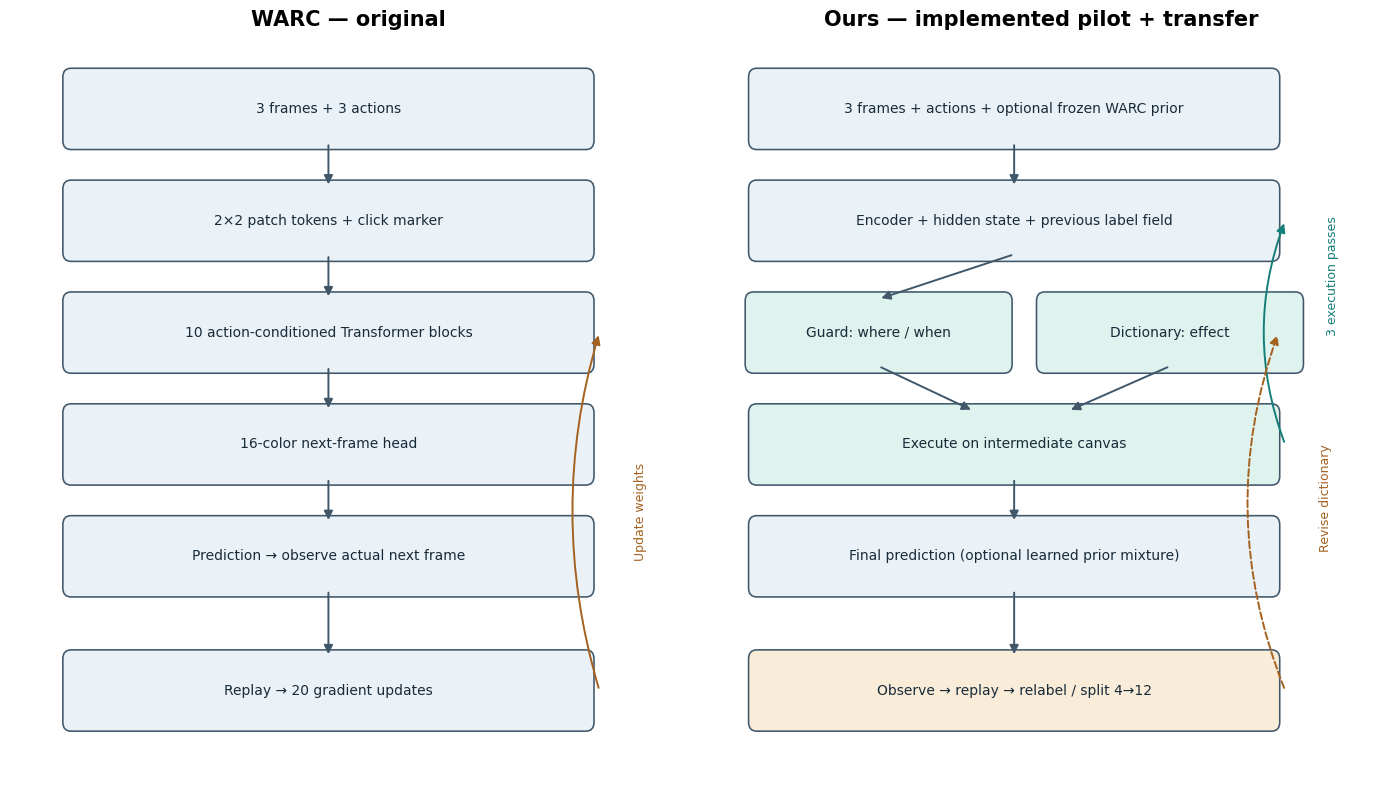

In [18]:
if globals().get("RUN_ARCHIVE", False):
    pass  # keeps comment-only historical cells syntactically valid
    import matplotlib.pyplot as plt
    from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

    fig, axes = plt.subplots(1, 2, figsize=(14, 8), facecolor='white')
    def node(ax, xy, label, color='#eaf1f7', w=.76, h=.085):
        x,y=xy
        ax.add_patch(FancyBboxPatch((x-w/2,y-h/2),w,h,boxstyle='round,pad=.012',
                     facecolor=color,edgecolor='#40576a',linewidth=1.15))
        ax.text(x,y,label,ha='center',va='center',fontsize=10,color='#182b39')
    def arrow(ax,a,b,color='#40576a',rad=0,ls='-'):
        ax.add_patch(FancyArrowPatch(a,b,arrowstyle='-|>',mutation_scale=13,
                    color=color,connectionstyle=f'arc3,rad={rad}',linestyle=ls,linewidth=1.4))
    for ax in axes:
        ax.set(xlim=(0,1),ylim=(0,1)); ax.axis('off')
    a,b=axes
    a.set_title('WARC — original',fontsize=15,weight='bold')
    for y,t in [( .90,'3 frames + 3 actions'),(.75,'2×2 patch tokens + click marker'),
                (.60,'10 action-conditioned Transformer blocks'),(.45,'16-color next-frame head'),
                (.30,'Prediction → observe actual next frame'),(.12,'Replay → 20 gradient updates')]:
        node(a,(.47,y),t)
    for y,z in zip([.90,.75,.60,.45,.30],[.75,.60,.45,.30,.12]):
        arrow(a,(.47,y-.045),(.47,z+.045))
    arrow(a,(.87,.12),(.87,.60),'#a56120',-.15)
    a.text(.93,.36,'Update weights',rotation=90,ha='center',va='center',fontsize=9,color='#a56120')
    b.set_title('Ours — implemented pilot + transfer',fontsize=15,weight='bold')
    node(b,(.46,.90),'3 frames + actions + optional frozen WARC prior')
    node(b,(.46,.75),'Encoder + hidden state + previous label field')
    node(b,(.26,.60),'Guard: where / when','#def3ee',w=.37)
    node(b,(.69,.60),'Dictionary: effect','#def3ee',w=.37)
    node(b,(.46,.45),'Execute on intermediate canvas','#def3ee')
    node(b,(.46,.30),'Final prediction (optional learned prior mixture)')
    node(b,(.46,.12),'Observe → replay → relabel / split 4→12','#f9ecd8')
    arrow(b,(.46,.855),(.46,.795)); arrow(b,(.46,.705),(.26,.645))
    arrow(b,(.26,.555),(.40,.495)); arrow(b,(.69,.555),(.54,.495))
    arrow(b,(.46,.405),(.46,.345)); arrow(b,(.46,.255),(.46,.165))
    arrow(b,(.86,.45),(.86,.75),'#147e78',-.19)
    b.text(.93,.60,'3 execution passes',rotation=90,ha='center',fontsize=9,color='#147e78')
    arrow(b,(.86,.12),(.85,.60),'#a56120',-.19,'--')
    b.text(.92,.31,'Revise dictionary',rotation=90,ha='center',fontsize=9,color='#a56120')
    fig.tight_layout(); plt.show()

## 2 · Set up (Colab or Kaggle)

Select GPU; enable Internet on Kaggle. L4/A100 preferred. T4 uses a logged FP32 fallback for upstream WARC (including Muon). The notebook uses one GPU. Run cells in order; failed commands raise immediately. Source is pinned to the audited commit, not a moving branch.

In [19]:
if globals().get("RUN_ARCHIVE", False):
    pass  # keeps comment-only historical cells syntactically valid
    import os, sys, subprocess
    from pathlib import Path
    import torch
    assert torch.cuda.is_available(), 'Enable a GPU accelerator and reconnect.'
    print(torch.cuda.get_device_name(0), torch.__version__, 'BF16:',torch.cuda.is_bf16_supported())
    WORK=Path('/kaggle/working' if Path('/kaggle/working').exists() else '/content')/'recursive_research'
    WORK.mkdir(parents=True,exist_ok=True)
    def run(*args):
        subprocess.run([str(x) for x in args],check=True)
    REPO=WORK/'fastai'
    if not (REPO/'.git').exists():
        run('git','clone','--depth','1','--branch','research/recursive-world-model',
            'https://github.com/shekhawatxyz/fastai-2022',REPO)
    run('git','-C',REPO,'fetch','--depth','1','origin','2529f513d3eb68b26295d9ddf69d4346b2a0e4c4')
    run('git','-C',REPO,'checkout','--detach','2529f513d3eb68b26295d9ddf69d4346b2a0e4c4')
    SCRIPT=REPO/'experiments/recursive_world/recursive_world.py'
    run(sys.executable,'-m','py_compile',SCRIPT)

Tesla T4 2.11.0+cu130 BF16: True
M	experiments/recursive_world/recursive_world.py


From https://github.com/shekhawatxyz/fastai-2022
 * branch            2529f513d3eb68b26295d9ddf69d4346b2a0e4c4 -> FETCH_HEAD
HEAD is now at 2529f51 Isolate frozen-prior cache, record exposure counts, support full game sweep and T4 Muon fallback


## 3 · Prove the plumbing first

Predict: normalized probabilities, causal inference, hard execution, nonzero weight updates, label birth, and transfer smoke tests must pass. Synthetic color transfer is a sanity test, not evidence of real-world superiority.

In [20]:
if globals().get("RUN_ARCHIVE", False):
    pass  # keeps comment-only historical cells syntactically valid
    import ast
    import subprocess
    import textwrap

    # Restore pristine source from the local Git repository.
    src = subprocess.check_output(
        [
            "git", "-C", str(REPO), "show",
            "HEAD:experiments/recursive_world/recursive_world.py"
        ],
        text=True
    )

    tree = ast.parse(src)

    world = next(
        n for n in tree.body
        if isinstance(n, ast.ClassDef) and n.name == "World"
    )

    forward = next(
        n for n in world.body
        if isinstance(n, ast.FunctionDef) and n.name == "forward"
    )

    # Replace the entire method, not individual strings.
    replacement = """
    def forward(self, h, a, hard=False, details=False, prior=None):
        original = onehot(h[:, -1])
        board = original

        features = [
            onehot(h, C+1).flatten(1, 2),
            actions(a, *h.shape[-2:])
        ]

        if self.transfer:
            assert prior is not None
            features.append(prior.float())

        base = self.enc(torch.cat(features, 1))
        hidden = base
        label = base.new_zeros((len(h), K, *h.shape[-2:]))

        table = self.effects.float().softmax(-1) if self.symbolic else None

        if hard and self.symbolic:
            table = F.one_hot(table.argmax(-1), O).float()

        for _ in range(self.passes):
            canvas = original if self.arm == "static" else board

            # Recursive label feedback is NOT the pretrained prior.
            label_prior = torch.zeros_like(label) if self.arm == "static" else label

            hidden = hidden + self.refine(
                torch.cat((base, hidden, canvas, label_prior), 1)
            )

            logits = self.guard(hidden).float()

            if self.symbolic:
                logits = logits.masked_fill(
                    ~self.active[None, :, None, None], -1e9
                )

            q = logits.softmax(1)

            if hard:
                q = F.one_hot(
                    q.argmax(1), q.shape[1]
                ).movedim(-1, 1).float()

            label = self.feedback(q)

            if self.arm == "direct":
                board = q
                continue

            with torch.autocast(h.device.type, enabled=False):
                w = q if table is None else torch.einsum(
                    "bkhw,ko->bohw", q, table
                )

                b, _, hh, ww = w.shape

                copy = torch.einsum(
                    "bcon,bon->bcn",
                    sources(canvas),
                    w[:, :len(OFF)].flatten(2)
                )

                board = copy.reshape(b, C, hh, ww) + w[:, len(OFF):]
                board = board / board.sum(1, keepdim=True).clamp_min(1e-8)

        if self.transfer:
            gate = self.mix(hidden).float().sigmoid()

            if hard:
                board = torch.where(
                    gate >= .5,
                    board,
                    F.one_hot(prior.argmax(1), C).movedim(-1, 1).float()
                )
            else:
                board = (1-gate)*prior.float() + gate*board

        return (board, q, table, canvas) if details else board
    """

    lines = src.splitlines()

    lines[forward.lineno-1:forward.end_lineno] = (
        textwrap.indent(replacement.strip(), "    ").splitlines()
    )

    src = "\n".join(lines) + "\n"

    # T4 precision compatibility.
    src = src.replace(
        "torch.cuda.is_bf16_supported()",
        "(torch.cuda.get_device_capability(0)[0] >= 8)"
    )

    compile(src, str(SCRIPT), "exec")
    SCRIPT.write_text(src)

    print("Forward method replaced successfully.", flush=True)

    # Run smoke test with full error reporting.
    result = subprocess.run(
        [
            sys.executable, "-u", str(SCRIPT),
            "--suite", "smoke",
            "--epochs", "4",
            "--seeds", "1",
            "--arms", "direct,copy,small,stale,grow",
            "--profile",
            "--out", str(WORK/"smoke")
        ],
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True
    )

    print(result.stdout, flush=True)
    print("Exit code:", result.returncode)

Forward method replaced successfully.
Self-tests passed
                 changed_acc  false_edit  exact  change_f1
task arm                                                  
move copy                0.5      0.1136    0.0     0.4603
     direct              0.5      0.1136    0.0     0.4603
     grow                0.5      0.1133    0.0     0.4607
     grow_hard           0.0      0.0000    0.0     0.0000
     small               0.5      0.1133    0.0     0.4607
     small_hard          0.0      0.0000    0.0     0.0000
     stale               0.5      0.1133    0.0     0.4607
     stale_hard          0.0      0.1616    0.0     0.1946

Published MechEval (NOT the replay proxy above):
              All_pct    EtC  not_reached_pct
episodic         32.9  109.0             76.8
WARC frozen      18.4  114.0             85.5
WARC scratch     35.0  105.0             51.2
WARC GRU         24.0   87.0             84.1
DreamerV3        25.9  114.0             90.8
WARC TTT         69.1   74.0

## 4 · Real WARC comparison

The public dataset mirror is a convenient default; official recording byte identity is unverified. For definitive public-data experiments, set DATA to the extracted [ARC Prize Public Demo dataset](https://arcprize.org/blog/arc-agi-3-human-dataset) folder and check WARC's data SHA256SUMS. Both models get exactly the same causal stream. No model sees the target before prediction. Fold checkpoints exclude the tested game. Each recording starts with fresh weights; this is a replay proxy, not the official MechEval protocol.

Predict: the transfer model should initially track the frozen checkpoint. If gains come only from transfer rather than rule induction, the identical direct-transfer control will expose this. Evaluate quality and speed, including the separate teacher-cache cost.

In [21]:
if globals().get("RUN_ARCHIVE", False):
    pass  # keeps comment-only historical cells syntactically valid
    import os, sys, subprocess
    import pandas as pd

    assert torch.cuda.device_count() >= 2

    # Smaller WARC: preserve its architecture, reduce its size.
    src = SCRIPT.read_text()

    old = '**{k:mc[k] for k in UNIFIED_DEFAULTS if k in mc})'
    assert old in src

    src = src.replace(
        old,
        'embed_dim=64, depth=2, num_heads=4, mlp_dim=128)'
    )

    # Allow running just the WARC comparator.
    src = src.replace(
        'arms=args.arms.split(",");',
        'arms=list(filter(None,args.arms.split(",")));'
    )

    TINY = SCRIPT.with_name("tiny_warc.py")
    TINY.write_text(src)

    run(sys.executable, '-m', 'py_compile', TINY)

    # Identical real ARC data and update budgets.
    common = [
        '--suite', 'arc',
        '--warc-root', str(WORK/'WARC'),
        '--games', 'ls20',
        '--sessions', '1',
        '--limit', '12',
        '--seeds', '1',
        '--steps', '20'
    ]

    if globals().get('DATA'):
        common += ['--data', str(DATA)]

    def launch(gpu, script, extra):
        env = dict(os.environ, CUDA_VISIBLE_DEVICES=str(gpu))
        return subprocess.Popen(
            [sys.executable, '-u', str(script), *common, *extra],
            env=env
        )

    # GPU 0: our architecture and its ablations.
    p0 = launch(0, SCRIPT, [
        '--arms', 'direct,copy,small,stale,grow',
        '--skip-warc',
        '--profile',
        '--out', str(WORK/'small_ours')
    ])

    # GPU 1: reduced-size WARC from scratch.
    p1 = launch(1, TINY, [
        '--arms', '',
        '--warc-arms', 'scratch',
        '--out', str(WORK/'small_warc')
    ])

    codes = [p0.wait(), p1.wait()]
    assert codes == [0, 0], codes

    # Compare both experiments.
    ours = pd.read_csv(WORK/'small_ours/scores.csv')
    warc = pd.read_csv(WORK/'small_warc/scores.csv')
    warc['arm'] = warc['arm'].replace(
        'WARC scratch', 'WARC tiny'
    )

    assert set(ours.session) == set(warc.session)

    results = pd.concat([ours, warc])
    display(results.groupby('arm')[
        ['changed_acc', 'exact', 'false_edit', 'update_s']
    ].mean().round(4))

    print((WORK/'small_ours/profile.txt').read_text())

Self-tests passed
Self-tests passed
WARC BF16 unsupported; both models use FP32. Not identical to published precision.
WARC BF16 unsupported; both models use FP32. Not identical to published precision.


ls20 94b39ad1-a025-4d18-a20a-a14eb2aa1b6a.recording direct 0 complete
                      changed_acc  false_edit   exact  change_f1
game arm                                                        
ls20 WARC scratch          0.3846      0.0915  0.0000     0.3947
     keep                  0.0000      0.0000  0.0833     0.0000
     local retrieval       0.0000      0.0005  0.0833     0.0000

Published MechEval (NOT the replay proxy above):
              All_pct    EtC  not_reached_pct
episodic         32.9  109.0             76.8
WARC frozen      18.4  114.0             85.5
WARC scratch     35.0  105.0             51.2
WARC GRU         24.0   87.0             84.1
DreamerV3        25.9  114.0             90.8
WARC TTT         69.1   74.0             18.8
ls20 94b39ad1-a025-4d18-a20a-a14eb2aa1b6a.recording copy 0 complete
ls20 94b39ad1-a025-4d18-a20a-a14eb2aa1b6a.recording small 0 complete
ls20 94b39ad1-a025-4d18-a20a-a14eb2aa1b6a.recording stale 0 complete
ls20 94b39ad1-a025-4d18-a20

/usr/local/lib/python3.13/dist-packages/torch/profiler/profiler.py:224: UserWarning: Warning: Profiler clears events at the end of each cycle.Only events from the current cycle will be reported.To keep events across cycles, set acc_events=True.
  _warn_once(


-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                                   Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg     Self CUDA   Self CUDA %    CUDA total  CUDA time avg       CPU Mem  Self CPU Mem      CUDA Mem  Self CUDA Mem    # of Calls  
-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                       recursive_update         0.00%       0.000us         0.00%       0.000us       0.000us      31.270ms       142.39%      31.270ms      31.270ms           0 B           0 B           0 B           0 

,changed_acc,exact,false_edit,update_s
arm,,,,
WARC tiny,0.3846,0.0000,0.0915,0.7763
copy,0.5402,0.0000,0.0751,0.5048
direct,0.5857,0.0000,0.1271,0.3697
grow,0.2920,0.0000,0.0634,0.5364
keep,0.0000,0.0833,0.0000,NaN
local retrieval,0.0000,0.0833,0.0005,NaN
small,0.2937,0.0000,0.0634,0.5285
stale,0.2500,0.0000,0.1012,0.5415


-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                                   Name    Self CPU %      Self CPU   CPU total %     CPU total  CPU time avg     Self CUDA   Self CUDA %    CUDA total  CUDA time avg       CPU Mem  Self CPU Mem      CUDA Mem  Self CUDA Mem    # of Calls  
-------------------------------------------------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  ------------  
                                       recursive_update         0.00%       0.000us         0.00%       0.000us       0.000us      31.270ms       142.39%      31.270ms      31.270ms           0 B           0 B           0 B           0 

## 5 · Read the results before increasing compute

Primary metric: changed-cell accuracy averaged per recording, then game. Exact-frame and false-edit rates prevent a model from winning by painting everything. Time and number of examples/updates are separate, not silently equated. A fixed 20-step budget matches the published WARC update count, not FLOPs.

changed_acc   exact  false_edit  change_f1
game arm                                                        
ls20 WARC frozen           0.7856  0.0000      0.0012     0.8185
     copy                  0.6731  0.0000      0.0423     0.5022
     direct                0.6965  0.0000      0.0686     0.4797
     grow                  0.3229  0.0000      0.0509     0.1902
     keep                  0.0000  0.0417      0.0000     0.0000
     local retrieval       0.0836  0.0417      0.0021     0.0817
     transfer_direct       0.8654  0.0000      0.0076     0.7242
     transfer_grow         0.7937  0.0000      0.0014     0.8261

,predict_s,update_s,teacher_cache_s
arm,,,
WARC frozen,0.0267,0.0000,NaN
copy,0.0043,0.4980,0.0000
direct,0.0035,0.3572,0.0000
grow,0.0047,0.5310,0.0000
keep,NaN,NaN,NaN
local retrieval,NaN,NaN,NaN
transfer_direct,0.0040,0.3788,0.1107
transfer_grow,0.0056,0.5582,0.1107


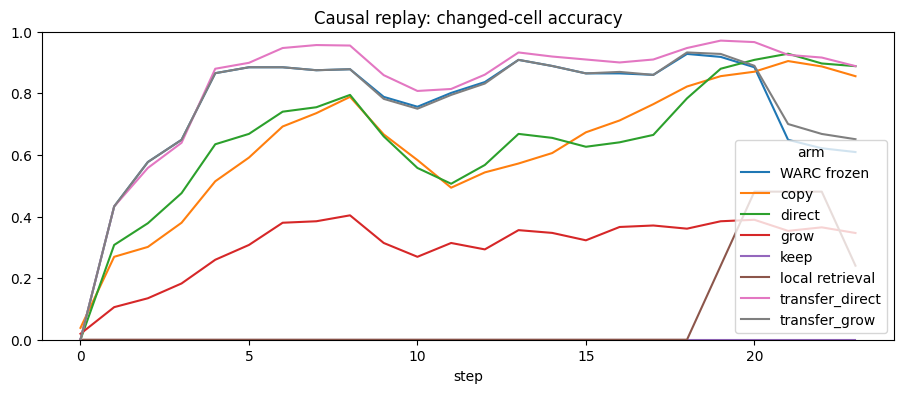

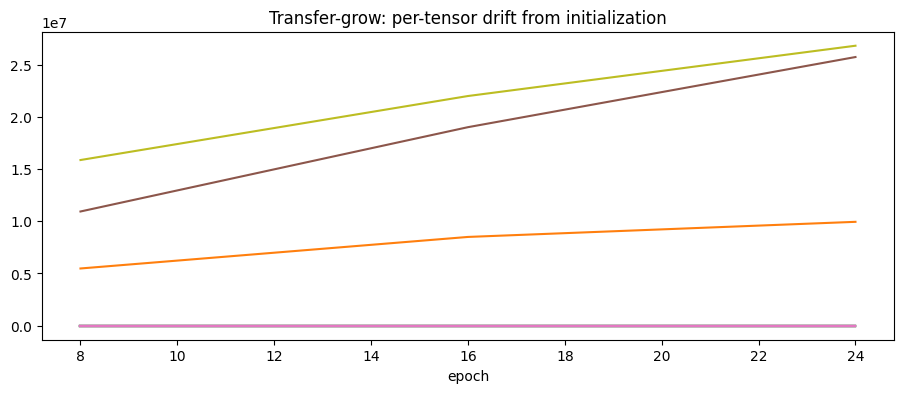

,game,session,arm,seed,epoch,slot,active,primitive,confidence,entropy
36,ls20,94b39ad1-a025-4d18-a20a-a14eb2aa1b6a.recording,transfer_grow,0,8,0,True,0,0.212337,3.135592
37,ls20,94b39ad1-a025-4d18-a20a-a14eb2aa1b6a.recording,transfer_grow,0,8,1,True,13,0.214456,3.132631
38,ls20,94b39ad1-a025-4d18-a20a-a14eb2aa1b6a.recording,transfer_grow,0,8,2,True,5,0.221815,3.118681
39,ls20,94b39ad1-a025-4d18-a20a-a14eb2aa1b6a.recording,transfer_grow,0,8,3,True,8,0.227963,3.105034
40,ls20,94b39ad1-a025-4d18-a20a-a14eb2aa1b6a.recording,transfer_grow,0,8,4,True,8,0.228860,3.103016
41,ls20,94b39ad1-a025-4d18-a20a-a14eb2aa1b6a.recording,transfer_grow,0,8,5,True,8,0.228860,3.103016
48,ls20,94b39ad1-a025-4d18-a20a-a14eb2aa1b6a.recording,transfer_grow,0,16,0,True,0,0.222443,3.114161
49,ls20,94b39ad1-a025-4d18-a20a-a14eb2aa1b6a.recording,transfer_grow,0,16,1,True,13,0.210800,3.139254
50,ls20,94b39ad1-a025-4d18-a20a-a14eb2aa1b6a.recording,transfer_grow,0,16,2,True,5,0.234016,3.091364
51,ls20,94b39ad1-a025-4d18-a20a-a14eb2aa1b6a.recording,transfer_grow,0,16,3,True,8,0.232614,3.094701


Artifacts: /kaggle/working/recursive_research/pilot


In [22]:
if globals().get("RUN_ARCHIVE", False):
    pass  # keeps comment-only historical cells syntactically valid
    import pandas as pd
    import matplotlib.pyplot as plt
    from IPython.display import display
    def report(folder):
        p=WORK/folder
        scores=pd.read_csv(p/'scores.csv')
        cols=['changed_acc','exact','false_edit','change_f1']
        paired=scores.groupby(['game','session','arm','seed'])[cols].mean().groupby(['game','session','arm']).mean()
        display(paired.groupby(['game','arm']).mean().round(4))
        display(scores.groupby('arm')[['predict_s','update_s','teacher_cache_s']].mean().round(4))
        scores.groupby(['step','arm']).changed_acc.mean().unstack().rolling(4,min_periods=1).mean().plot(
            figsize=(11,4),ylim=(0,1),title='Causal replay: changed-cell accuracy')
        plt.show()
        drift=pd.read_csv(p/'weight_drift.csv')
        drift[drift.arm=='transfer_grow'].pivot_table(index='epoch',columns='parameter',values='relative_init').plot(
            legend=False,title='Transfer-grow: per-tensor drift from initialization',figsize=(11,4))
        plt.show()
        display(pd.read_csv(p/'vocabulary.csv').query('arm == "transfer_grow" and active == True').tail(24))
        if (p/'profile.txt').exists(): print((p/'profile.txt').read_text())
        print('Artifacts:',p)
        return paired
    pilot=report('pilot')

## 6 · Scale only after pilot passes

Frozen configuration: 128 causal exposures per recording (or fewer if exhausted), 2 recordings per game, 3 seeds. Run the 25 public games by fold. Do not tune on these results and then call them untouched; reserve independent games/recordings for confirmation. The run is expensive; start one fold/game at a time if GPU quota is limited. More exposures can be tested after checking replay memory. This is a fixed-budget public replay evaluation, not the private ARC competition or the unavailable annotated MechEval scorer.

**Acceptance:** transfer-grow must beat WARC TTT on the same transitions, not only the frozen model; improve exact accuracy without materially increasing false edits; compare with transfer-direct, transfer-stale, transfer-small, transfer-fixed. Report paired game-level intervals, not independent-cell p-values. If only the ensemble wins, attribute the extra compute explicitly. Don't change five things at once: first test this, then try pretraining our own encoder, better operator primitives, or learned metarules.

In [23]:
if globals().get("RUN_ARCHIVE", False):
    pass  # keeps comment-only historical cells syntactically valid
    # Uncomment only when the pilot completes. Set separate output directories per fold.
    # run(*base,'--games','all','--sessions','2','--limit','128','--seeds','3',
    #     '--arms','direct,copy,grow','--transfer',
    #     '--transfer-arms','direct,fixed,small,stale,grow',
    #     '--warc-arms','frozen,ttt,scratch','--profile','--out',WORK/'full')
    # full=report('full')

In [25]:
if globals().get("RUN_ARCHIVE", False):
    pass  # keeps comment-only historical cells syntactically valid
    # Paired game-cluster bootstrap on the complete sweep; no significance claim on a one-game pilot.
    import numpy as np
    def paired_delta(paired, candidate='transfer_grow', baseline='WARC ttt'):
        game=paired['changed_acc'].unstack('arm').groupby('game').mean().dropna(subset=[candidate,baseline])
        delta=(game[candidate]-game[baseline]).to_numpy()
        assert len(delta)>=10, 'Too few independent games for a useful interval.'
        rng=np.random.default_rng(42)
        boot=rng.choice(delta,(10000,len(delta)),replace=True).mean(1)
        return dict(games=len(delta),difference_pp=100*delta.mean(),ci95_pp=(100*np.quantile(boot,[.025,.975])).tolist())
    # print(paired_delta(full))

## Published reference only — MechEval

| Method | All mechanic accuracy | Exposures to criterion | Not reached |
|---|---:|---:|---:|
| WARC frozen | 18.4% | 114 | 85.5% |
| WARC GRU | 24.0% | 87 | 84.1% |
| DreamerV3 | 25.9% | 114 | 90.8% |
| Episodic retrieval | 32.9% | 109 | 76.8% |
| WARC scratch | 35.0% | 105 | 51.2% |
| WARC TTT | 69.1% | 74 | 18.8% |

Source: [upstream evaluation table](https://github.com/third-intelligence/WARC#evaluation). Never compare a live replay score directly with these numbers. The actual baseline runs in section 4.

**Development status:** source reviewed against upstream; GPU integration not executed in the authoring environment. This is an executable research candidate with built-in tests, not a verified result.

In [27]:
if globals().get("RUN_ARCHIVE", False):
    pass  # keeps comment-only historical cells syntactically valid
    import shutil
    from IPython.display import FileLink

    shutil.make_archive(
        "/kaggle/working/pilot_results",
        "zip",
        "/kaggle/working/recursive_research/pilot"
    )

    display(FileLink("/kaggle/working/pilot_results.zip"))

/kaggle/working/pilot_results.zip